# Лабораторная работа 2: «Разработка сверточной нейронной сети с использованием PyTorch»

## Выполнил студент 
ФИО: **Рштуни Владислав Дмитриевич**

Группа: **3825М1сФИ1**

--- 


## Цель работы

**Цель работы** - разработать и обучить сверточную нейронную сеть для задачи классификации изображений на наборе данных [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) с использованием фреймворка PyTorch.

---

## Задачи работы

Выполнение лабораторной работы предполагает решение следующих задач:

1. Загрузить набор данных CIFAR-10 и выполнить предобработку данных, если это необходимо.
2. Реализовать сверточную нейронную сеть с использованием фреймворка PyTorch.
3. Выбрать подходящую функцию потерь и настроить гиперпараметры обучения.
4. Обучить реализованную нейронную сеть и провести оценку качества ее работы.

---

## Требования к результатам выполнения работы

1. **Структура и содержимое Jupyter Notebook**:
    - Вывести размерности данных: количество примеров в каждой выборке, форму одного изображения и меток.
    - Показать несколько изображений с метками классов, чтобы подтвердить корректность загрузки.
    - Реализовать архитектуру нейронной сети с использованием фреймворка PyTorch.
    - Настроить архитектуру сети и гиперпараметры обучения (количество и размеры слоев, скорость обучения, размер пачки данных, количество эпох и так далее).
    - Вывести ошибку классификации и точность на тренировочном наборе данных по окончании каждой эпохи.
    - По окончании обучения вывести ошибку классификации и точность на тестовом наборе данных.
    - Построить график изменения ошибки в процессе обучения.

2. **Выбор архитектуры**:
    - Необходимо использовать **сверточные** архитектуры нейронных сетей.
    - Разрешается воспроизвести известную архитектуру (например, VGG, ResNet и т.д.) или предложить собственную.
    - Сеть должна быть описана **собственным классом** и собрана из базовых слоев PyTorch. Брать готовую реализацию архитектуры - из `torchvision.models`, с GitHub или из любого другого источника - нельзя.

---

## Оценивание

- Количество баллов за лабораторную работу рассчитывается по формуле:  
  $\text{баллы} = 10 \times \text{знания} \times \text{точность}$, 

  $\text{знания} \in [0, 1]$ - оценка уровня понимания материала, 
  $\text{точность} \in [0, 1]$ - оценка точности решения задачи. Например, точность классификации 90% - это 0.9.

## Используемые библиотеки

Встроенные модули:

1. [os](https://docs.python.org/3/library/os.html)
2. [time](https://docs.python.org/3/library/time.html)

Классические библиотеки:

1. [numpy](https://numpy.org/)
2. [matplotlib](https://matplotlib.org/)

Сторонние библиотеки (Deep Learning):

1. [torch](https://pytorch.org/)
2. [torchvision](https://pytorch.org/)

Установка:

```bash
pip install numpy matplotlib
```

---

Установка PyTorch:

1. PyTorch для GPU от NVIDIA

```bash
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu{версия_cuda}
```
Пример для cuda 13.4 (cu134)
```bash
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu134
```

2. PyTorch для GPU от AMD

```bash
pip install torch torchvision --index-url https://download.pytorch.org/whl/rocm{версия_rocm}
```
Пример для rocm 10.0 (rocm10.0)
```bash
pip install torch torchvision --index-url https://download.pytorch.org/whl/rocm10.0
```

3. PyTorch для CPU
```bash
pip3 install torch torchvision --index-url https://download.pytorch.org/whl/cpu
```

# Тестовый стенд

Hardware Information:
- **Процессор:** AMD Ryzen 5 5600H (6C/12T)
- **Оперативная память:** 2 × 8 GB DDR4
- **Графическая карта:** AMD Radeon RX 6600M 8 GB

Software Information:
- **ОС:** Arch Linux x86_64
- **Ядро:** Linux 7.2.8-arch1-2
- **Python:** 3.14.7
- **PyTorch:** 2.14.0 (для GPU от AMD)
- **ROCm:** 7.2 (RX 6600M официально не поддерживается)

In [ ]:
import os
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# ВНИМАНИЕ: блок только для локального запуска на AMD RDNA 2
# (на машинах с NVIDIA/CPU этот блок удалить)

# Костыль для видеокарт AMD RDNA 2:
#   - gfx1032: RX 6600 / 6600 XT / 6650 XT,
#              а также мобильные RX 6600M / 6650M
#   - gfx1031: RX 6700 / 6700 XT / 6750 XT,
#              а также мобильные 6700M / 6800M
#
# Проверено только на ROCm 7.2.
# В ROCm 10.0 поддержку RDNA 2 полностью убрали.
#
# Маскируем карту под gfx1030 (RX 6800 / 6900 — официально
# поддерживаются ROCm), иначе ROCm её не видит.

import os
os.environ['HSA_OVERRIDE_GFX_VERSION'] = '10.3.0'

In [ ]:
torch.cuda.manual_seed_all(42)
torch.manual_seed(42)
np.random.seed(42)

NUM_CLASSES = 10

labels_map = {
    0: "airplane", 1: "automobile", 2: "bird", 3: "cat", 4: "deer",
    5: "dog", 6: "frog", 7: "horse", 8: "ship", 9: "truck",
}

BATCH_SIZE = 128
EPOCHS = 30
LR = 0.05

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Используемое устройство: {device}')

(null): No such file or directory
(null): No such file or directory


Используемое устройство: cuda


(null): No such file or directory
(null): No such file or directory


## 2. Загрузка и предобработка данных

Датасет CIFAR-10 загружается через `torchvision.datasets`. Изображения приводятся к тензорам формата `[C, H, W]`: `v2.ToImage()` + `v2.ToDtype(torch.float32, scale=True)` переводят пиксели в `float32` и масштабируют в `[0, 1]`, после чего выполняется нормализация по средним и стандартным отклонениям датасета. Для тренировочной выборки добавлены аугментации `RandomCrop(32, padding=4)` и `RandomHorizontalFlip()`.

In [2]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)

train_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.RandomCrop(32, padding=4),
    v2.RandomHorizontalFlip(),
    v2.Normalize(mean, std),
])

test_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std),
])

train_data = datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=train_transform
)

test_data = datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=test_transform
)

trainloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
testloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [3]:
print(f'Размерность изображений для обучения: {len(train_data)}')
print(f'Размерность изображений для тестирования: {len(test_data)}\n')

print(f'Форма одного изображения: {train_data[0][0].shape}')
print(f'Количество классов: {NUM_CLASSES}')

Размерность изображений для обучения: 50000
Размерность изображений для тестирования: 10000

Форма одного изображения: torch.Size([3, 32, 32])
Количество классов: 10


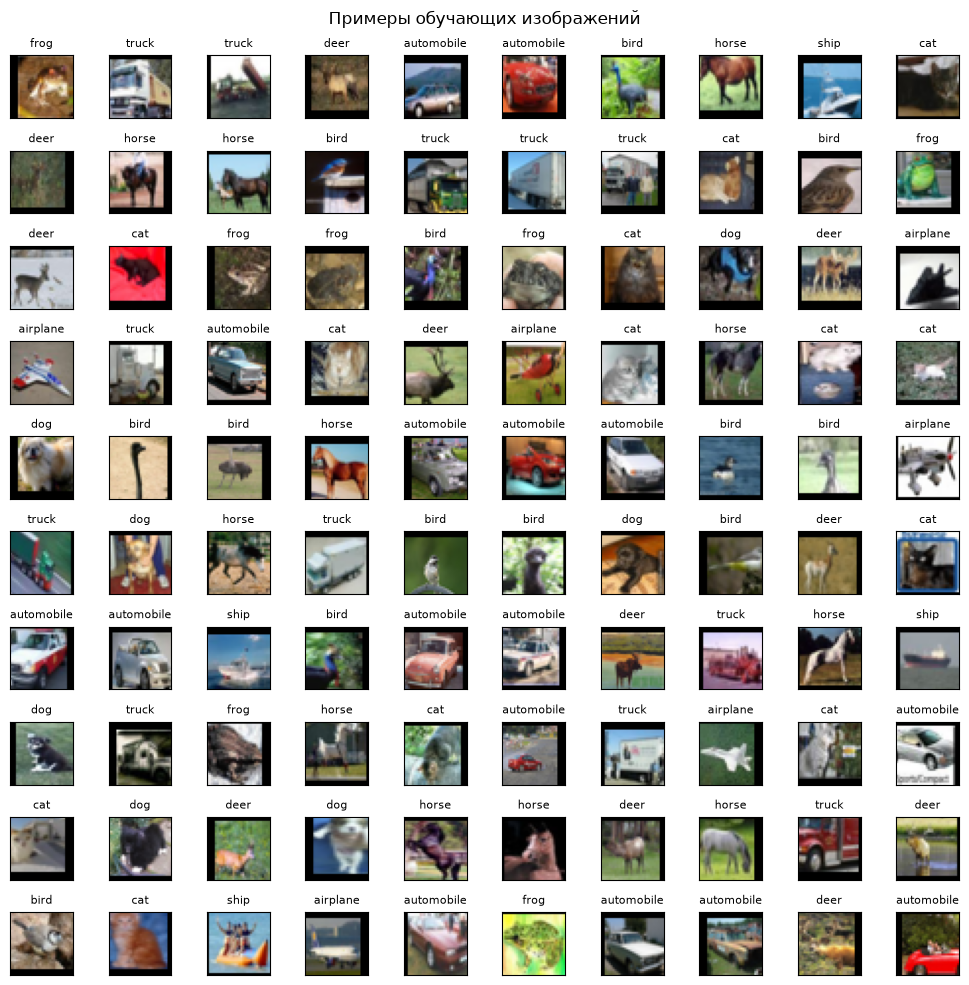

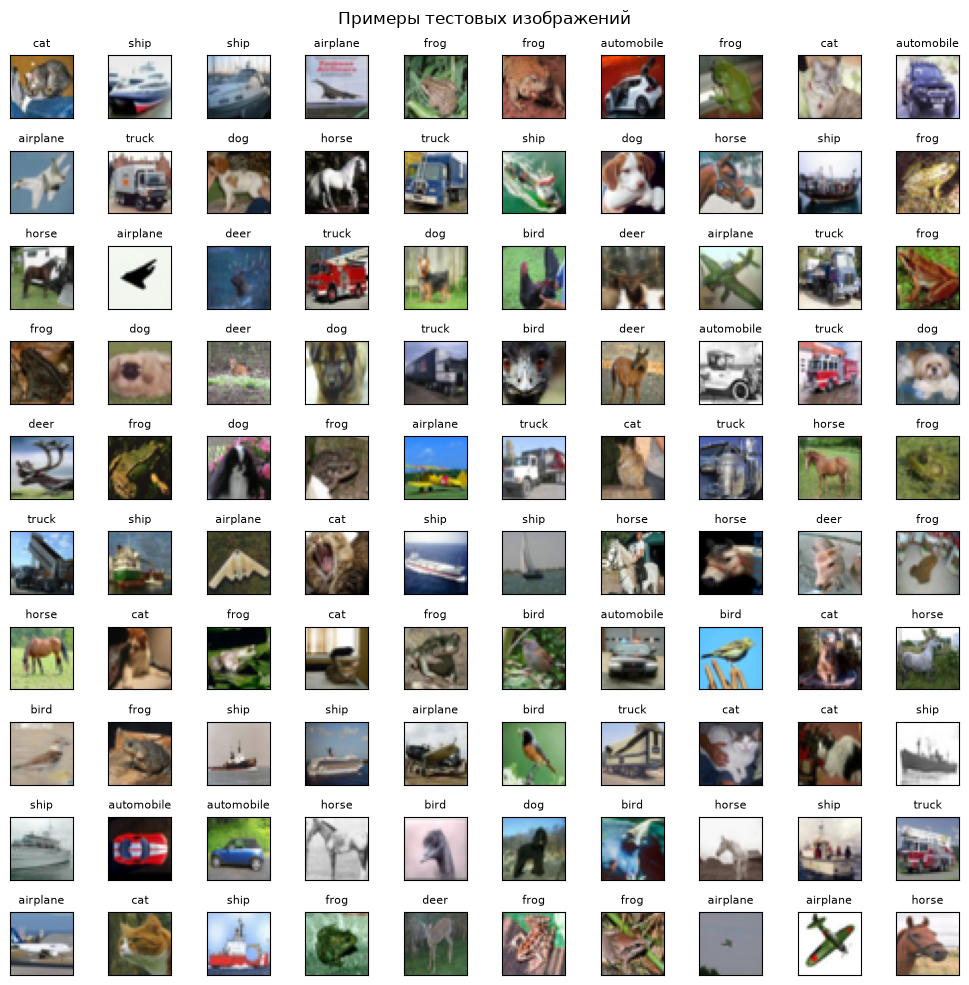

In [4]:
def denormalize(img_tensor):
    """[C,H,W] нормализованный тензор -> [H,W,C] картинка в [0,1]."""
    t = img_tensor.clone()
    for c in range(3):
        t[c] = t[c] * std[c] + mean[c]
    return t.permute(1, 2, 0).clamp(0, 1).numpy()

def show_images(data, title, num=100):
    num_x, num_y = 10, 10
    fig, axes = plt.subplots(num_y, num_x, figsize=(10, 10))
    fig.suptitle(title)
    plt.setp(axes, xticks=[], yticks=[])

    for i, ax in enumerate(axes.flat):
        if i >= min(num, len(data)):
            break
        ax.imshow(denormalize(data[i][0]))
        ax.set_title(labels_map[data[i][1]], fontsize=8)

    plt.tight_layout()
    plt.show()

show_images(train_data, 'Примеры обучающих изображений', num=100)
show_images(test_data, 'Примеры тестовых изображений', num=100)

## 3. Реализация слоёв и сети

Реализуем собственную архитектуру на основе ResNet, адаптированную под CIFAR-10 (изображения 32×32):

- `BasicBlock` — базовый остаточный блок: две свёртки 3×3 с BatchNorm, shortcut-соединение, после сложения — ReLU.
- `CIFARResNet` — сеть с тремя стадиями (16, 32, 64 канала, по 2 блока в каждой), без maxpool на входе (stem — Conv 3×3, stride 1), глобальным average pooling и линейным классификатором на 10 классов.

```
Структура:
    Conv 3x3 (16)  -> 32x32
    Stage 1 (16)   -> 32x32
    Stage 2 (32)   -> 16x16
    Stage 3 (64)   ->  8x8
    GlobalAvgPool -> FC(10)
```



Для улучшения сходимости веса сверточных слоев инициализированы методом Kaiming Normal, а слои BatchNorm — единичными весами и нулевыми смещениями.

In [ ]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.downsample = downsample

    def forward(self, x):
        identity = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return F.relu(out + identity)


class CIFARResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.in_planes = 16
        self.conv1 = nn.Conv2d(3, 16, 3, 1, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)

        self.layer1 = self._make_layer(16, blocks=2, stride=1)
        self.layer2 = self._make_layer(32, blocks=2, stride=2)
        self.layer3 = self._make_layer(64, blocks=2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, planes, blocks, stride):
        downsample = None
        if stride != 1 or self.in_planes != planes:
            downsample = nn.Sequential(
                nn.Conv2d(self.in_planes, planes, 1, stride, bias=False),
                nn.BatchNorm2d(planes),
            )

        layers = [BasicBlock(self.in_planes, planes, stride, downsample)]
        self.in_planes = planes
        layers += [BasicBlock(planes, planes) for _ in range(1, blocks)]
        return nn.Sequential(*layers)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

## 3. Функция потерь, оптимизатор и гиперпараметры

Используем `CrossEntropyLoss` (включает в себя `Softmax`).

Оптимизатор: `SGD` с моментом и L2-регуляризацией (`weight_decay`).

Scheduler: `CosineAnnealingLR` — плавное косинусное снижение скорости обучения на протяжении всех `EPOCHS` эпох.

In [6]:
criterion = nn.CrossEntropyLoss()

model = CIFARResNet(num_classes=NUM_CLASSES).to(device)
optimizer = optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=5e-4)

scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

## 5. Функции обучения и оценки

Определим функции для прохождения одной эпохи обучения (`train_one_epoch`) и для вычисления метрик (`evaluate`). 

In [7]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, targets)

        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

    return running_loss / total, correct / total

## 6. Цикл обучения

Запускаем процесс обучения. По окончании каждой эпохи выводим `loss` и `accuracy` на тренировочном и тестовом наборах.

In [8]:
train_losses, train_accs = [], []
test_losses,  test_accs  = [], []

start = time.time()

for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_one_epoch(model, trainloader, criterion, optimizer, device)
    te_loss, te_acc = evaluate(model, testloader, criterion, device)
    scheduler.step()

    train_losses.append(tr_loss)
    train_accs.append(tr_acc)
    test_losses.append(te_loss)
    test_accs.append(te_acc)

    print(f"Epoch [{epoch+1:2d}/{EPOCHS}]  "
          f"| train loss: {tr_loss:.4f}, train acc: {tr_acc*100:5.2f}%  "
          f"| test loss: {te_loss:.4f}, test acc: {te_acc*100:5.2f}%")

elapsed = time.time() - start
print(f"\nОбучение заняло {elapsed/60:.1f} мин")

Epoch [ 1/30]  | train loss: 1.5371, train acc: 42.57%  | test loss: 1.4672, test acc: 49.80%
Epoch [ 2/30]  | train loss: 1.0682, train acc: 61.78%  | test loss: 1.0595, test acc: 62.20%
Epoch [ 3/30]  | train loss: 0.9002, train acc: 68.14%  | test loss: 0.9893, test acc: 66.17%
Epoch [ 4/30]  | train loss: 0.7812, train acc: 72.66%  | test loss: 0.8133, test acc: 72.38%
Epoch [ 5/30]  | train loss: 0.6920, train acc: 75.96%  | test loss: 0.9332, test acc: 70.43%
Epoch [ 6/30]  | train loss: 0.6428, train acc: 77.78%  | test loss: 0.6945, test acc: 75.67%
Epoch [ 7/30]  | train loss: 0.5943, train acc: 79.55%  | test loss: 0.7912, test acc: 74.79%
Epoch [ 8/30]  | train loss: 0.5718, train acc: 80.43%  | test loss: 0.7807, test acc: 73.65%
Epoch [ 9/30]  | train loss: 0.5449, train acc: 81.19%  | test loss: 0.7381, test acc: 75.70%
Epoch [10/30]  | train loss: 0.5150, train acc: 82.33%  | test loss: 0.7000, test acc: 76.89%
Epoch [11/30]  | train loss: 0.4933, train acc: 82.99%  | te

## 7. Финальная оценка и графики

Выводим финальные метрики на тестовой выборке и строим графики изменения функции потерь и точности в процессе обучения.

Финальная ошибка на тесте (cross-entropy): 0.3285
Финальная точность на тесте: 89.05%



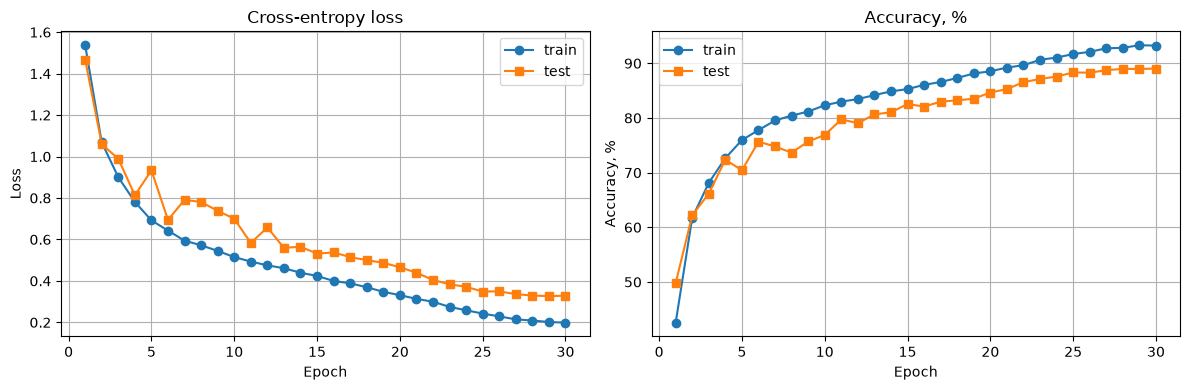

In [9]:
final_test_loss, final_test_acc = evaluate(model, testloader, criterion, device)
print(f"Финальная ошибка на тесте (cross-entropy): {final_test_loss:.4f}")
print(f"Финальная точность на тесте: {final_test_acc*100:.2f}%\n")

eps = np.arange(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(eps, train_losses, marker='o', label='train')
axes[0].plot(eps, test_losses, marker='s', label='test')
axes[0].set_title('Cross-entropy loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True)

axes[1].plot(eps, [acc * 100 for acc in train_accs], marker='o', label='train')
axes[1].plot(eps, [acc * 100 for acc in test_accs], marker='s', label='test')
axes[1].set_title('Accuracy, %')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy, %')
axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()

## Предсказания на тестовой выборке

Визуализируем первые 100 правильно и первые 100 неправильно классифицированных моделью изображений из тестовой выборки.

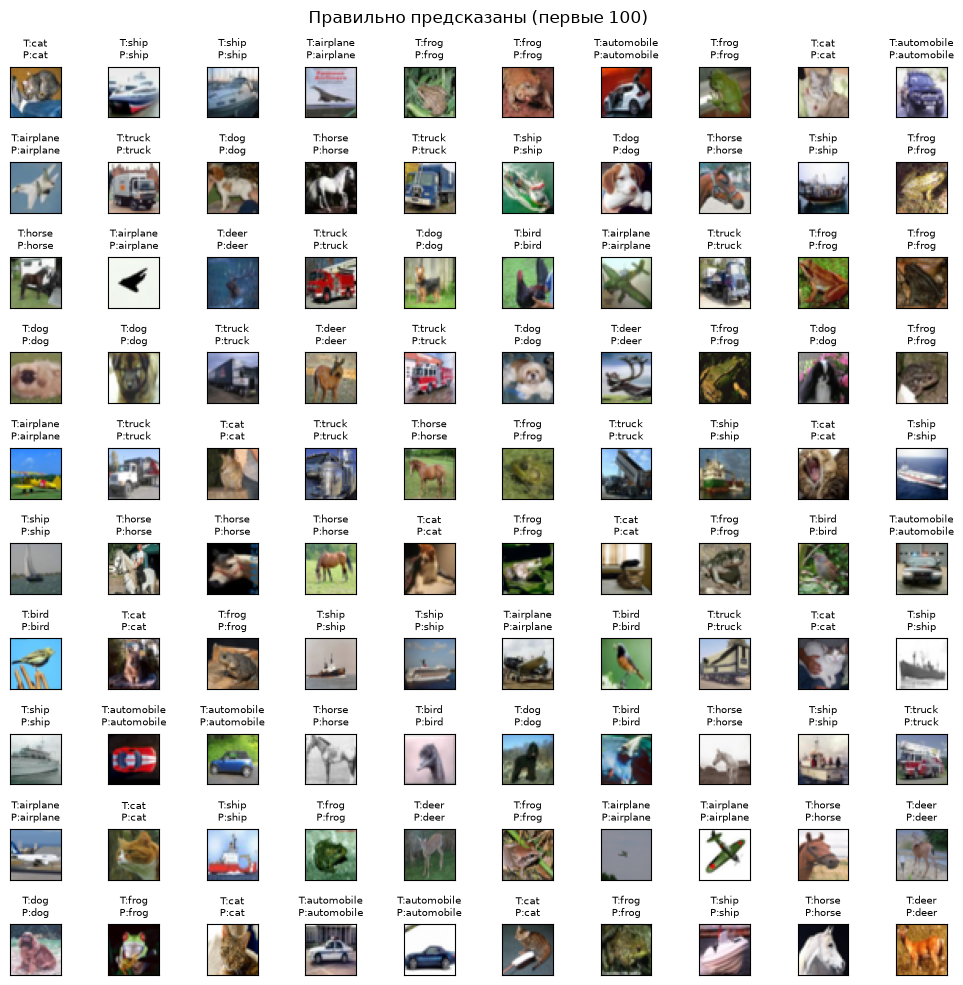

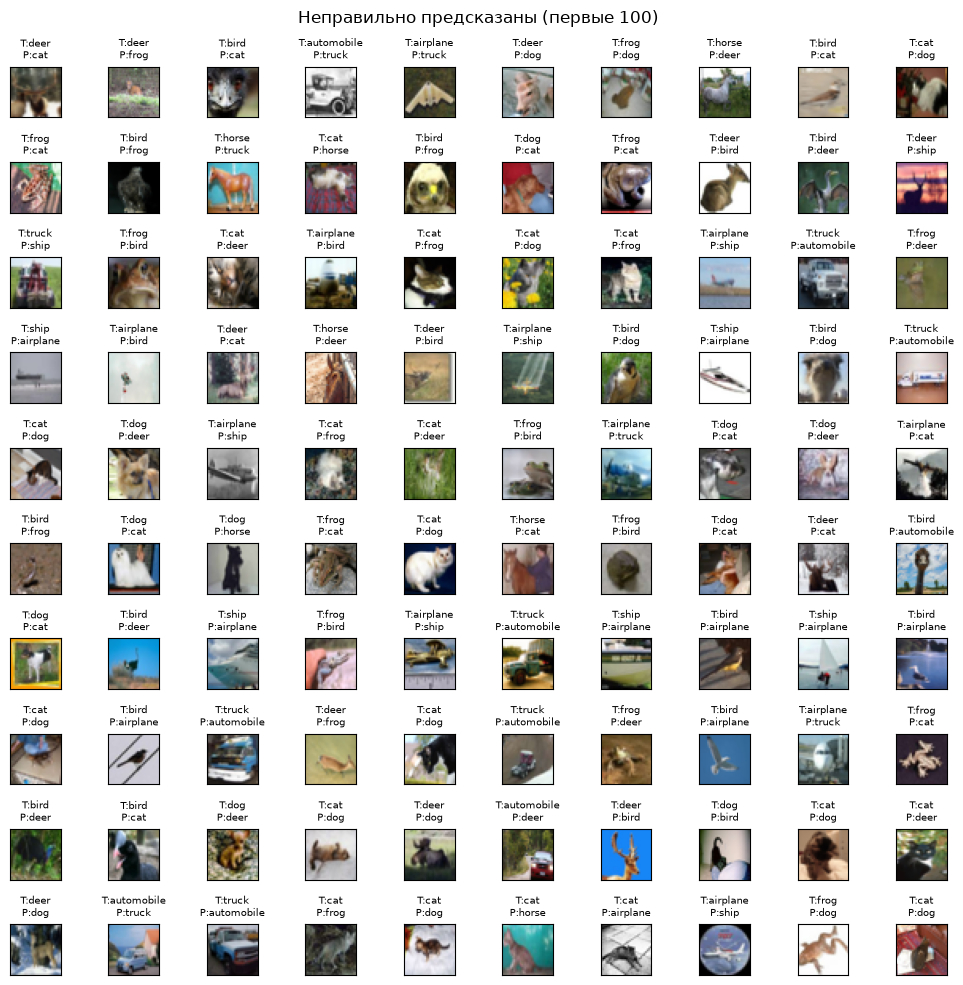

In [10]:
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, targets in testloader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

correct_mask = (all_preds == all_targets)
incorrect_mask = ~correct_mask

correct_idx = np.where(correct_mask)[0]
incorrect_idx = np.where(incorrect_mask)[0]

def show_test_predictions(data, indices, preds, title, num=100):
    num_x, num_y = 10, 10
    fig, axes = plt.subplots(num_y, num_x, figsize=(10, 10))
    fig.suptitle(title)
    plt.setp(axes, xticks=[], yticks=[])

    for i, ax in enumerate(axes.flat):
        if i >= min(num, len(indices)):
            break
        idx = indices[i]
        img = denormalize(data[idx][0])
        ax.imshow(img)
        true_label = labels_map[data[idx][1]]
        pred_label = labels_map[preds[idx]]
        ax.set_title(f"T:{true_label}\nP:{pred_label}", fontsize=7)
        
    plt.tight_layout()
    plt.show()

show_test_predictions(test_data, correct_idx, all_preds, 'Правильно предсказаны (первые 100)', num=100)
show_test_predictions(test_data, incorrect_idx, all_preds, 'Неправильно предсказаны (первые 100)', num=100)